In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from mytorch import Tensor
from mytorch.layer import Linear
from mytorch.activation import relu, sigmoid, leaky_relu, tanh
from mytorch.optimizer import SGD
from mytorch.loss import CategoricalCrossEntropy
from mytorch.loss import MeanSquaredError

In [20]:
#TODO
FILE_PATH = 'diabetes.csv'

In [21]:
#don't change this cell
column_names = [f"Feature_{i}" for i in range(1, 9)] + ["Diagnosis"]
df = pd.read_csv(FILE_PATH, header=1, names=column_names, usecols=range(0, 9))

# df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})

df.describe()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Diagnosis
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [22]:
from torch.utils.data import TensorDataset

# Cell 5: Use numpy arrays instead of torch tensors
X = df.drop(columns=["Diagnosis"]).values.astype(np.float64)
y = df["Diagnosis"].values.astype(np.float64).reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train_dataset = TensorDataset(X_train, y_train)
# test_dataset = TensorDataset(X_test, y_test)

In [23]:
# #TODO
# train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
# test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=True)

In [24]:
class MLP:
    def __init__(self, input_size=8, activation=relu):
        self.fc1 = Linear(input_size, 128, need_bias=True)
        self.fc2 = Linear(128, 64, need_bias=True)
        self.fc3 = Linear(64, 32, need_bias=True)
        self.fc4 = Linear(32, 16, need_bias=True)
        self.fc5 = Linear(16, 1, need_bias=True)
        self.activation = activation
        
        self.layers = [self.fc1, self.fc2, self.fc3, self.fc4, self.fc5]

    def forward(self, x: Tensor) -> Tensor:
        x = self.activation(self.fc1.forward(x))
        x = self.activation(self.fc2.forward(x))
        x = self.activation(self.fc3.forward(x))
        x = self.activation(self.fc4.forward(x))
        x = sigmoid(self.fc5.forward(x))
        return x

In [25]:
input_size = X_train.shape[1]
NUM_EPOCHS = 250

(613, 8) (613, 1)
Epoch 1/250, Loss: 0.4433, Accuracy: 0.3409
Test Accuracy: 0.6299

Epoch 2/250, Loss: 0.9446, Accuracy: 0.6427
Test Accuracy: 0.3961

Epoch 3/250, Loss: 0.3951, Accuracy: 0.3768
Test Accuracy: 0.6039

Epoch 4/250, Loss: 0.3633, Accuracy: 0.6378
Test Accuracy: 0.3247

Epoch 5/250, Loss: 0.6580, Accuracy: 0.3654
Test Accuracy: 0.6364

Epoch 6/250, Loss: 0.8542, Accuracy: 0.6574
Test Accuracy: 0.4416

Epoch 7/250, Loss: 0.3475, Accuracy: 0.4258
Test Accuracy: 0.6169

Epoch 8/250, Loss: 0.3290, Accuracy: 0.6313
Test Accuracy: 0.4416

Epoch 9/250, Loss: 0.3587, Accuracy: 0.4323
Test Accuracy: 0.6299

Epoch 10/250, Loss: 0.4662, Accuracy: 0.6509
Test Accuracy: 0.3831

Epoch 11/250, Loss: 0.4888, Accuracy: 0.3556
Test Accuracy: 0.6299

Epoch 12/250, Loss: 0.5543, Accuracy: 0.6574
Test Accuracy: 0.4026

Epoch 13/250, Loss: 0.3961, Accuracy: 0.4078
Test Accuracy: 0.6299

Epoch 14/250, Loss: 0.4152, Accuracy: 0.6591
Test Accuracy: 0.4545

Epoch 15/250, Loss: 0.3780, Accuracy: 0

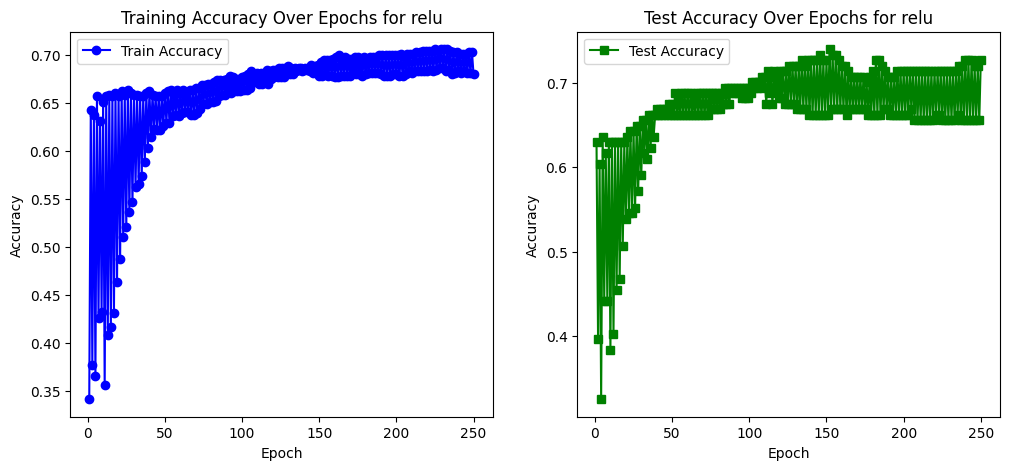

(613, 8) (613, 1)
Epoch 1/250, Loss: 0.4115, Accuracy: 0.3491
Test Accuracy: 0.3117
Epoch 2/250, Loss: 0.3977, Accuracy: 0.3475
Test Accuracy: 0.3312
Epoch 3/250, Loss: 0.3851, Accuracy: 0.3524
Test Accuracy: 0.3377
Epoch 4/250, Loss: 0.3737, Accuracy: 0.3556
Test Accuracy: 0.3636
Epoch 5/250, Loss: 0.3633, Accuracy: 0.3752
Test Accuracy: 0.3636
Epoch 6/250, Loss: 0.3541, Accuracy: 0.3931
Test Accuracy: 0.3701
Epoch 7/250, Loss: 0.3459, Accuracy: 0.3964
Test Accuracy: 0.4091
Epoch 8/250, Loss: 0.3387, Accuracy: 0.4192
Test Accuracy: 0.4351
Epoch 9/250, Loss: 0.3324, Accuracy: 0.4388
Test Accuracy: 0.4481
Epoch 10/250, Loss: 0.3270, Accuracy: 0.4470
Test Accuracy: 0.4740
Epoch 11/250, Loss: 0.3222, Accuracy: 0.4666
Test Accuracy: 0.5000
Epoch 12/250, Loss: 0.3179, Accuracy: 0.4894
Test Accuracy: 0.5130
Epoch 13/250, Loss: 0.3142, Accuracy: 0.4959
Test Accuracy: 0.5195
Epoch 14/250, Loss: 0.3108, Accuracy: 0.5057
Test Accuracy: 0.5325
Epoch 15/250, Loss: 0.3078, Accuracy: 0.5139
Test Acc

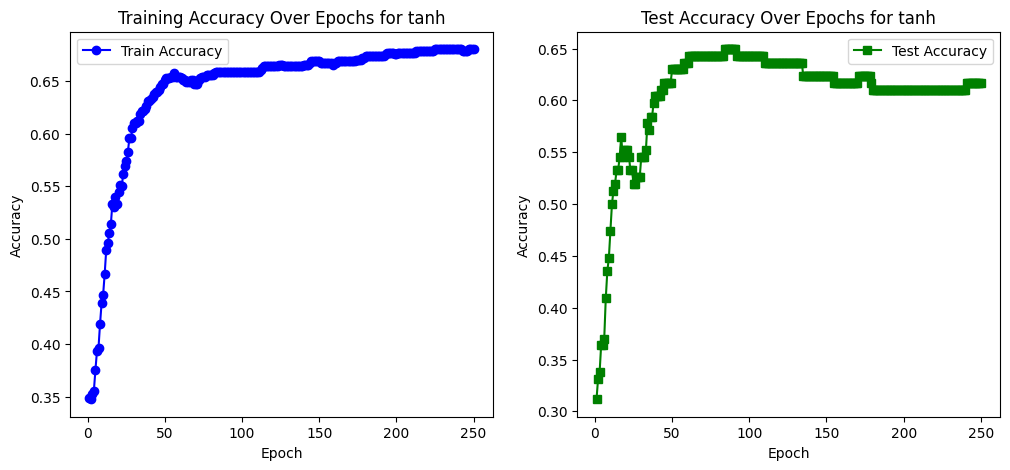

(613, 8) (613, 1)
Epoch 1/250, Loss: 0.4236, Accuracy: 0.3426
Test Accuracy: 0.3701
Epoch 2/250, Loss: 0.4228, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 3/250, Loss: 0.4220, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 4/250, Loss: 0.4212, Accuracy: 0.3426
Test Accuracy: 0.3701
Epoch 5/250, Loss: 0.4204, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 6/250, Loss: 0.4195, Accuracy: 0.3426
Test Accuracy: 0.3701
Epoch 7/250, Loss: 0.4188, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 8/250, Loss: 0.4180, Accuracy: 0.3426
Test Accuracy: 0.3701
Epoch 9/250, Loss: 0.4172, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 10/250, Loss: 0.4164, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 11/250, Loss: 0.4156, Accuracy: 0.3426
Test Accuracy: 0.3701
Epoch 12/250, Loss: 0.4148, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 13/250, Loss: 0.4141, Accuracy: 0.3426
Test Accuracy: 0.3701
Epoch 14/250, Loss: 0.4133, Accuracy: 0.3426
Test Accuracy: 0.3701

Epoch 15/250, Loss: 0.4125, Accuracy: 0.3426


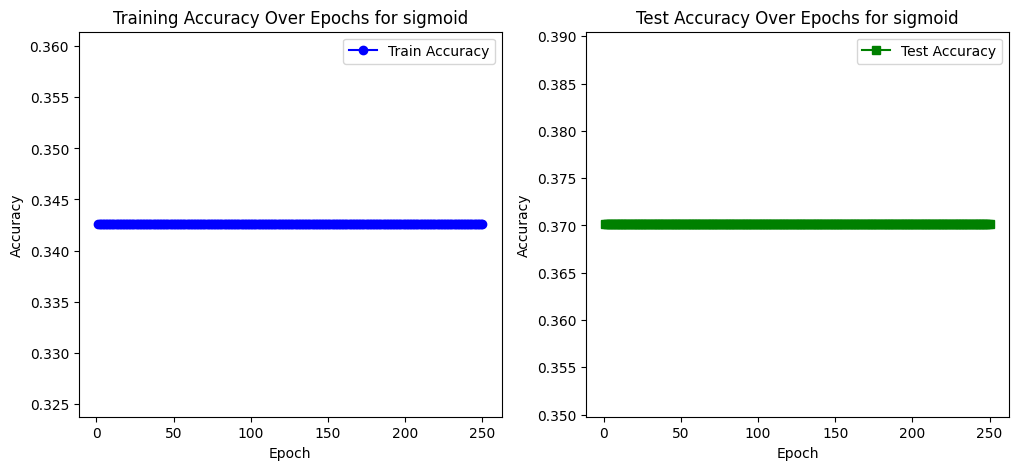

(613, 8) (613, 1)
Epoch 1/250, Loss: 0.4494, Accuracy: 0.3458
Test Accuracy: 0.6299

Epoch 2/250, Loss: 0.9858, Accuracy: 0.6476
Test Accuracy: 0.4091

Epoch 3/250, Loss: 0.3966, Accuracy: 0.3719
Test Accuracy: 0.5974

Epoch 4/250, Loss: 0.3292, Accuracy: 0.6150
Test Accuracy: 0.5455

Epoch 5/250, Loss: 0.3479, Accuracy: 0.5318
Test Accuracy: 0.6299

Epoch 6/250, Loss: 0.6009, Accuracy: 0.6476
Test Accuracy: 0.3636

Epoch 7/250, Loss: 0.5529, Accuracy: 0.3426
Test Accuracy: 0.6364

Epoch 8/250, Loss: 0.7784, Accuracy: 0.6591
Test Accuracy: 0.4091

Epoch 9/250, Loss: 0.3512, Accuracy: 0.3948
Test Accuracy: 0.6234

Epoch 10/250, Loss: 0.3825, Accuracy: 0.6525
Test Accuracy: 0.3701

Epoch 11/250, Loss: 0.4375, Accuracy: 0.3605
Test Accuracy: 0.6364

Epoch 12/250, Loss: 0.5233, Accuracy: 0.6558
Test Accuracy: 0.3766

Epoch 13/250, Loss: 0.4156, Accuracy: 0.3752
Test Accuracy: 0.6299

Epoch 14/250, Loss: 0.4550, Accuracy: 0.6574
Test Accuracy: 0.3831

Epoch 15/250, Loss: 0.4058, Accuracy: 0

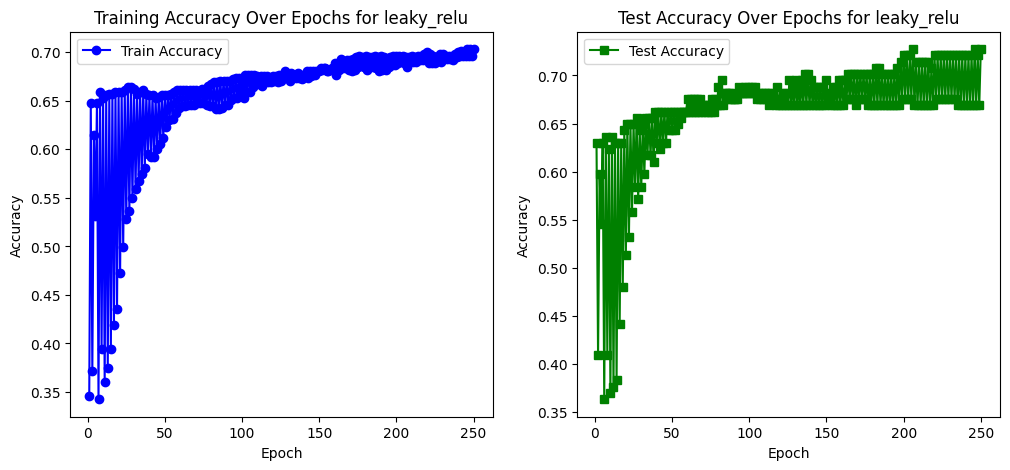

In [26]:
for activation in [relu, tanh, sigmoid, leaky_relu]:  
    np.random.seed(42)
    model = MLP(input_size, activation=activation)
    optimizer = SGD(model.layers, learning_rate=0.005)
    
    # Cell 9: Training loop with full-batch (manual, no DataLoader)
    train_accuracy_list = []
    test_accuracy_list = []
    
    X_train_t = Tensor(X_train)
    y_train_t = Tensor(y_train)
    
    X_test_t = Tensor(X_test)
    y_test_t = Tensor(y_test)
    
    print(X_train_t.shape, y_train_t.shape)
    
    for epoch in range(NUM_EPOCHS):
        # Train
        optimizer.zero_grad()
        outputs = model.forward(X_train_t)
        loss = CategoricalCrossEntropy(outputs, y_train_t)
        loss.backward()
        optimizer.step()
        
        # Train accuracy
        predicted = (outputs.data > 0.5).astype(float)
        corrects = (predicted == y_train).sum()
        accuracy = corrects / y_train.shape[0]
        train_accuracy_list.append(accuracy)
        print(f"Epoch {epoch+1}/{NUM_EPOCHS}, Loss: {loss.data:.4f}, Accuracy: {accuracy:.4f}")
        
        # Test (no grad)
        outputs_test = model.forward(X_test_t)
        predicted_test = (outputs_test.data > 0.5).astype(float)
        correct_test = (predicted_test == y_test).sum()
        accuracy_test = correct_test / y_test.shape[0]
        test_accuracy_list.append(accuracy_test)
        print(f"Test Accuracy: {accuracy_test:.4f}\n")
        
        
    # don't change this cell
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(range(1, NUM_EPOCHS+1), train_accuracy_list, marker='o', linestyle='-', color='b', label="Train Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Training Accuracy Over Epochs for {activation.__name__}")
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(range(1, NUM_EPOCHS+1), test_accuracy_list, marker='s', linestyle='-', color='g', label="Test Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Test Accuracy Over Epochs for {activation.__name__}")
    plt.legend()
    
    plt.show()

<div style="direction: rtl; text-align: right; font-family: Tahoma; font-size: 18px; line-height: 2; padding: 30px;">
    <p>در این آزمایش تأثیر چهار تابع فعال‌سازی مختلف بر عملکرد یک شبکه پرسپترون چندلایه بر روی دیتاست دیابت بررسی شد.</p>
    <p>نتایج نشان داد که تابع رلو و لیکی رلو به‌طور قابل‌توجهی بهتر از دو تابع دیگر عمل می‌کنند و به دقت تست حدود <strong>۷۳–۷۴٪</strong> دست یافتند.</p>
    <p>تابع تانژانت هیپربولیک عملکرد متوسطی داشت و دچار کمی بیش‌برازش شد.</p>
    <p>اما تابع سیگموید کاملاً ناکام ماند و دقت آن در حدود ۳۴–۳۷٪ باقی ماند. دلیل اصلی این شکست، پدیده محو شدن گرادیان است. مشتق تابع سیگموید حداکثر ۰.۲۵ است و با عبور از دو لایه، گرادیان‌ها بیش از ۱۶ برابر کوچک می‌شوند. در نتیجه وزن‌های لایه اول تقریباً هیچ تغییری نکردند و شبکه عملاً یاد نگرفت.</p>
    <p>این آزمایش به خوبی نشان داد که چرا در شبکه‌های عصبی مدرن، استفاده از رلو و مشتقات آن به‌عنوان استاندارد پذیرفته شده است.</p>
</div>